#### AutoMPG
- 398 개의 instance
- 7 개의 feature
    - 연비를 target으로 설정
    - 입력 feature는 weight만 사용하여 선형회귀 모델 생성

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.preprocessing import MinMaxScaler

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

'cpu'

#### Define make_DataSet, train, evaluate, learning_curve

In [ ]:
def make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32):
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_tensor = torch.tensor(x_val, dtype= torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype= torch.float32).view(-1,1)

    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)

    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)

    return train_loader, x_val_tensor, y_val_tensor

In [ ]:
def train(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)  # dataloader가 사용하는 데이터셋의 샘플 수
    num_batches = len(dataloader)   # dataloader는 32, dataset은 100 개
    tr_loss = 0
    
    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches

    return tr_loss.item()

In [44]:
def evaluate(dataloader, model, loss_fn, optimizer, device):
    model.eval()
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            val_loss = loss_fn(pred, y).item()

    return val_loss, pred

In [12]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'train error', marker= '.')
    plt.plot(epochs, val_loss_list, label= 'val error', marker= '.')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

#### Input Dataset

In [ ]:
data = sns.load_dataset('mpg')

print(data.head())
print(data.shape)
print(data.isnull().sum())  # 무게에는 결측치 존재하지 않음

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
(398, 9)
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [32]:
# 자동차 무게와 연비만 선택
target = 'mpg'
feature = 'weight'
x = data.loc[:, [feature]]
# 단일변수회귀모델의 단순 x 데이터는 series로 출력 되기 때문에 
# 대괄호를 하나 더 붙인 [:, [feature]]으로 데이터프레임으로 변환
y = data.loc[:, target]

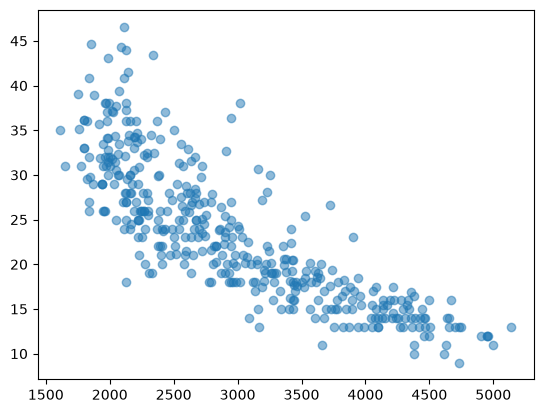

In [33]:
# 그래프 보기
plt.scatter(x, y, alpha=0.5)

In [34]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size= .2, random_state= 42)

scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)  
x_val = scaler.transform(x_val)

y_train = y_train.values
y_val = y_val.values

train_loader, test_loader = make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32)

In [57]:
# 모델 선언
# LR, EPOCH 등의 하이퍼파라미터 변경 시, model 선언 cell만 초기화할 수 있도록 같은 cell에 배치
LR = 1e-2
EPOCH = 50

n_feature = x.shape[1]
model = nn.Sequential(nn.Linear(n_feature, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
    ).to(device)
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr= LR)

In [ ]:
# 학습 / 검증
tr_loss_list, val_loss_list = [], []

for ep in range(EPOCH):
    tr_loss = train(train_loader, model, loss_fn, optimizer, device)
    val_loss, _ = evaluate(test_loader, model, loss_fn, optimizer, device)
    
    tr_loss_list.append(tr_loss)
    val_loss_list.append(val_loss)
    
    print(f'Epoch {ep+1}, train loss {tr_loss:.4f}, eval loss {val_loss:.4f}')

Epoch 1, train loss 581.2728, eval loss 498.3228
Epoch 2, train loss 544.5234, eval loss 459.2974
Epoch 3, train loss 500.2975, eval loss 411.3481
Epoch 4, train loss 446.4483, eval loss 353.9116
Epoch 5, train loss 382.1635, eval loss 289.9705
Epoch 6, train loss 313.5865, eval loss 224.5124
Epoch 7, train loss 247.8822, eval loss 165.1658
Epoch 8, train loss 189.5950, eval loss 121.1272
Epoch 9, train loss 148.0541, eval loss 93.9118
Epoch 10, train loss 123.0710, eval loss 81.6086
Epoch 11, train loss 112.0254, eval loss 77.1854
Epoch 12, train loss 104.8954, eval loss 74.1174
Epoch 13, train loss 100.1043, eval loss 70.5129
Epoch 14, train loss 95.4153, eval loss 66.3867
Epoch 15, train loss 90.6233, eval loss 62.4723
Epoch 16, train loss 86.0477, eval loss 58.9262
Epoch 17, train loss 81.4453, eval loss 55.2774
Epoch 18, train loss 77.0424, eval loss 51.8874
Epoch 19, train loss 72.7673, eval loss 48.1631
Epoch 20, train loss 68.3757, eval loss 44.7240
Epoch 21, train loss 63.9482

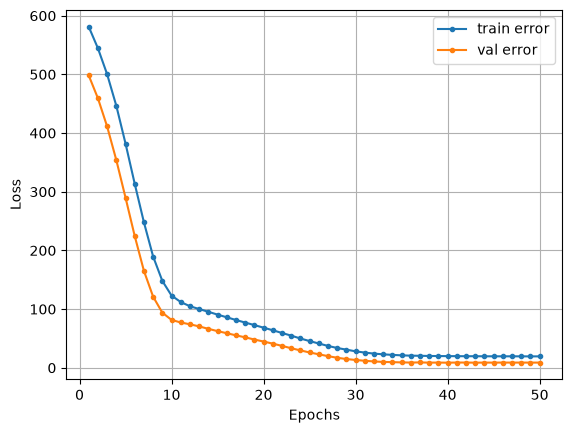

In [59]:
learning_curve(tr_loss_list, val_loss_list)

In [ ]:
# 예측 결과
_, pred = evaluate(test_loader, model, loss_fn, optimizer, device)


NameError: name 'y_val_ts' is not defined